In [ ]:
try:
    import dolfinx
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/fenicsx-install-release-complex.sh" -O "/tmp/fenicsx-install.sh" && bash "/tmp/fenicsx-install.sh"
    import dolfinx

In [ ]:
try:
    import meshio
except ImportError:
    !pip install meshio
    import meshio

In [ ]:
import requests

url = "https://storage.yandexcloud.net/storage-1-s/mesh.msh"
destination = "mesh.msh"

response = requests.get(url, stream=True)
with open(destination, "wb") as f:
    for chunk in response.iter_content(32768):
        if chunk:
            f.write(chunk)

print("Файл mesh.msh скачан успешно!")


Файл mesh.msh скачан успешно!


In [ ]:
import meshio
from mpi4py import MPI
import numpy as np

proc = MPI.COMM_WORLD.rank
def create_mesh(mesh, cell_type, prune_z=False):
    cells = mesh.get_cells_type(cell_type)
    cell_data = mesh.get_cell_data("gmsh:physical", cell_type)
    points = mesh.points[:, :2] if prune_z else mesh.points
    out_mesh = meshio.Mesh(points=points, cells={cell_type: cells},
    cell_data={"name_to_read": [cell_data.astype(np.int32)]})
    return out_mesh
if proc == 0:
    msh = meshio.read("mesh.msh")
    tetra_mesh = create_mesh(msh, "triangle", prune_z=True)
    triangle_mesh = create_mesh(msh, "line", prune_z=True)
    meshio.write("mesh.xdmf", tetra_mesh)
    meshio.write("mt.xdmf", triangle_mesh)
MPI.COMM_WORLD.barrier()

In [ ]:
from mpi4py import MPI
from dolfinx import fem
from dolfinx.io import XDMFFile
from dolfinx.fem import Constant, Function, functionspace, assemble_scalar, form
from dolfinx.fem.petsc import LinearProblem
from ufl import (Measure, TestFunction, TrialFunction, inner, grad,
                 jump, avg, FacetNormal, CellDiameter, SpatialCoordinate,
                 as_vector, exp, dot, dx, ds, dS, conj, div)
import numpy as np
import ufl
from petsc4py import PETSc

with XDMFFile(MPI.COMM_WORLD, "mesh.xdmf", "r") as xdmf:
    mesh = xdmf.read_mesh(name="Grid")
    ct = xdmf.read_meshtags(mesh, name="Grid")

mesh.topology.create_connectivity(mesh.topology.dim, mesh.topology.dim-1)

with XDMFFile(MPI.COMM_WORLD, "mt.xdmf", "r") as xdmf:
    ft = xdmf.read_meshtags(mesh, name="Grid")

dx = Measure('dx', domain=mesh, subdomain_data=ct)
ds = Measure('ds', domain=mesh, subdomain_data=ft)
dS = Measure('dS', domain=mesh)

V = functionspace(mesh, ("DG", 1))
W0 = functionspace(mesh, ("DG", 0))

k0 = 1.0
k = Constant(mesh, PETSc.ScalarType(k0 + 0j))

n_coef = Function(W0)
n_coef.x.array[:] = 1.0 + 0j
n_coef.x.array[ct.find(2)] = 10.0 + 0j

A = Function(W0)
A.x.array[:] = 1.0 + 0j
A.x.array[ct.find(2)] = 0.2 + 0j

x = SpatialCoordinate(mesh)
d = as_vector((1.0, 0.0))
u_i = exp(1j * k * dot(x, d))

u = TrialFunction(V)
v = TestFunction(V)

n = FacetNormal(mesh)
h = CellDiameter(mesh)
h_avg = (h("+") + h("-")) / 2.0

f = (
    div((1.0 - A) * grad(u_i))
    + k**2 * (1.0 - n_coef) * u_i
)

sigma = Constant(mesh, PETSc.ScalarType(6.0 + 0j))

# Объёмный вклад
a = (
     inner(A * grad(u), grad(v)) * dx
    - k**2 * inner(n_coef * u, v) * dx
    - inner(avg(A * grad(u)), jump(v, n)) * dS
    - inner(jump(u, n), avg(A * grad(v))) * dS
    + sigma / h_avg * avg(A)* inner( jump(u, n), jump(v, n)) * dS
    - 1j * k * inner(u, v) * ds
)

L = -inner(f, v) * dx

problem = LinearProblem(
    a, L, bcs=[],
    petsc_options={
        "ksp_type": "gmres",
        "ksp_rtol": 1e-8,
        "pc_type": "ilu",
        "ksp_max_it": 2000
    },
    petsc_options_prefix="helmholtz_"
)
uh = problem.solve()

In [ ]:
# @title Обработка данных
import pyvista
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Convert the DOLFINx mesh to a PyVista unstructured grid
pyvista.start_xvfb()
mesh.topology.create_connectivity(mesh.topology.dim, mesh.topology.dim)
p_mesh = pyvista.UnstructuredGrid(*dolfinx.plot.vtk_mesh(mesh, mesh.topology.dim))
pyvista_cells, cell_types, geometry = dolfinx.plot.vtk_mesh(V)
grid = pyvista.UnstructuredGrid(pyvista_cells, cell_types, geometry)

grid.point_data["u_s_real"] = uh.x.array.real
grid.point_data["u_s_imag"] = uh.x.array.imag

coords = grid.points
u_i_vals = np.exp(1j * k0 * coords[:, 0])

u_total = uh.x.array + u_i_vals

grid.point_data["u_i_real"] = u_i_vals.real
grid.point_data["u_i_imag"] = u_i_vals.imag

grid.point_data["u_real"] = u_i_vals.real + uh.x.array.real
grid.point_data["u_imag"] = u_i_vals.imag + uh.x.array.imag
grid.point_data["u_abs"]  = np.abs(u_total)

/tmp/ipython-input-487/3679893437.py:9: PyVistaDeprecationWarning: This function is deprecated and will be removed in future version of PyVista. Use vtk with osmesa instead.
  pyvista.start_xvfb()


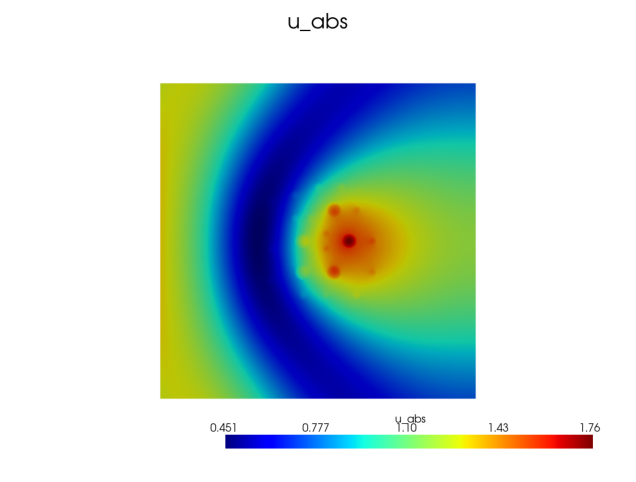

In [ ]:
# @title Решение $\text{Abs}(u)$
grid.set_active_scalars("u_abs")
p_abs = pyvista.Plotter(off_screen=True)
p_abs.add_text("u_abs", position="upper_edge", font_size=14, color="black")
p_abs.add_mesh(grid, cmap="jet", show_edges=False)
p_abs.view_xy()
figure = p_abs.screenshot("u_abs.png")

# вывод
img = mpimg.imread("u_abs.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

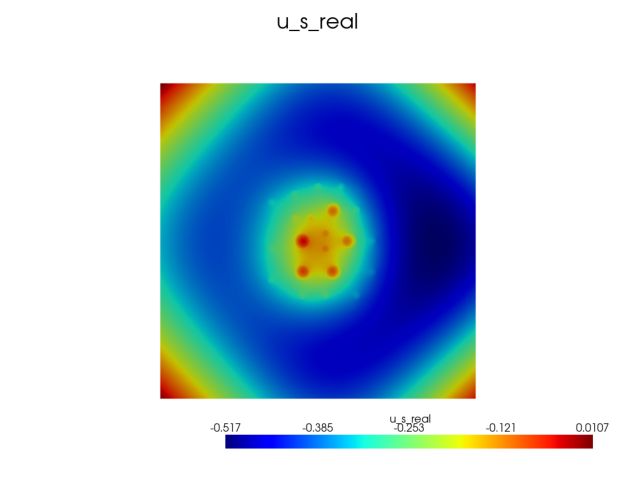

In [ ]:
# @title Решение $\text{Re}(u_s)$
_ = grid.set_active_scalars("u_s_real")

p_real = pyvista.Plotter(off_screen=True)
p_real.add_text("u_s_real", position="upper_edge", font_size=14, color="black")
p_real.add_mesh(grid, cmap="jet", show_edges=False)
p_real.view_xy()
figure = p_real.screenshot("u_s_real.png")

# вывод
img = mpimg.imread("u_s_real.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

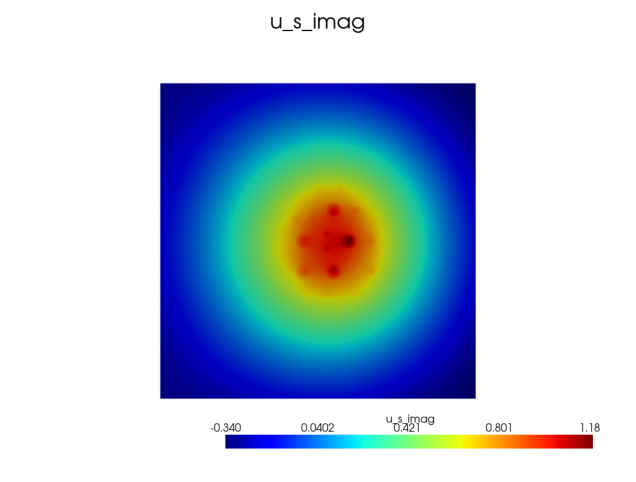

In [ ]:
# @title Решение $\text{Im}(u_s)$
_ = grid.set_active_scalars("u_s_imag")
p_imag = pyvista.Plotter(off_screen=True)
p_imag.add_text("u_s_imag", position="upper_edge", font_size=14, color="black")
p_imag.add_mesh(grid, cmap="jet", show_edges=False)
p_imag.view_xy()
figure = p_imag.screenshot("u_s_imag.png")

# вывод
img = mpimg.imread("u_s_imag.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")   # убрать оси
plt.show()